# Chapter 3: Dimensionality Reduction Techniques

**Reference:** John Sukup, *scikit-learn Cookbook*, Third Edition (2025).

This notebook follows the main topics of Chapter 3. The demonstrations are independently written and pair each code example with a short explanation of its output.

**Source:** John Sukup, *scikit-learn Cookbook*, Third Edition (Packt, 2025). The sections below follow the topics and selected examples presented in the book. Explanations and interpretations are summarized in original English.

## 1. Introduction to dimensionality reduction

High-dimensional data may be difficult to visualize and can contain correlated or redundant information. Reducing feature count can simplify exploration, although the compressed representation may lose details.

In [11]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
wine = load_wine()
X = StandardScaler().fit_transform(wine.data)
y = wine.target
print('Original dataset shape:', X.shape)
print('Classes:', sorted(set(y)))

Original dataset shape: (178, 13)
Classes: [np.int64(0), np.int64(1), np.int64(2)]


**Interpretation**

The wine dataset contains multiple measured features per sample and three known classes. Standardization is important because the features are expressed in different units.

## 2. Transforming datasets with PCA

Principal component analysis constructs orthogonal directions that capture as much feature variance as possible. Because it ignores the target labels, PCA is an unsupervised projection.

In [12]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
print('Reduced shape:', X_pca.shape)
print('Explained variance ratios:', pca.explained_variance_ratio_.round(3))
print('Cumulative variance:', round(sum(pca.explained_variance_ratio_),3))

Reduced shape: (178, 2)
Explained variance ratios: [0.362 0.192]
Cumulative variance: 0.554


**Interpretation**

The dataset is represented by two components instead of the original feature count. The cumulative explained-variance ratio indicates how much information, in the variance sense, those components retain.

## 3. Visualizing PCA results

Scatterplots of the first two principal components help explore broad structure. A two-dimensional display is easier to inspect but should not be mistaken for a perfect representation of the original measurements.

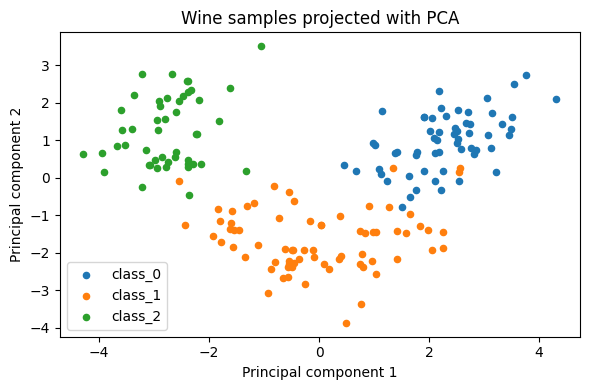

In [13]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))
for cls in sorted(set(y)):
    subset = X_pca[y==cls]
    plt.scatter(subset[:,0], subset[:,1], s=20, label=wine.target_names[cls])
plt.xlabel('Principal component 1'); plt.ylabel('Principal component 2')
plt.title('Wine samples projected with PCA'); plt.legend(); plt.tight_layout(); plt.show()

**Interpretation**

The plot shows the class groups in a plane defined by overall data variance. Visible grouping is informative, but some separation may still exist in components not shown here.

## 4. Maximizing class separability with LDA

Linear discriminant analysis uses class labels to find projections that increase between-class separation relative to variation within classes. For three classes, it can extract at most two discriminant axes.

In [14]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X,y)
print('LDA projection shape:', X_lda.shape)
print('Explained discriminant ratio:', lda.explained_variance_ratio_.round(3))

LDA projection shape: (178, 2)
Explained discriminant ratio: [0.687 0.313]


**Interpretation**

LDA also reduces the dataset to two dimensions, but unlike PCA it explicitly uses the labels. Its axes are chosen for discrimination, so they need not align with directions of highest total variance.

## 5. Differences between PCA and LDA

PCA summarizes variance without knowing the target. LDA searches for informative separation between known categories. Comparing projections illustrates why the intended task influences technique choice.

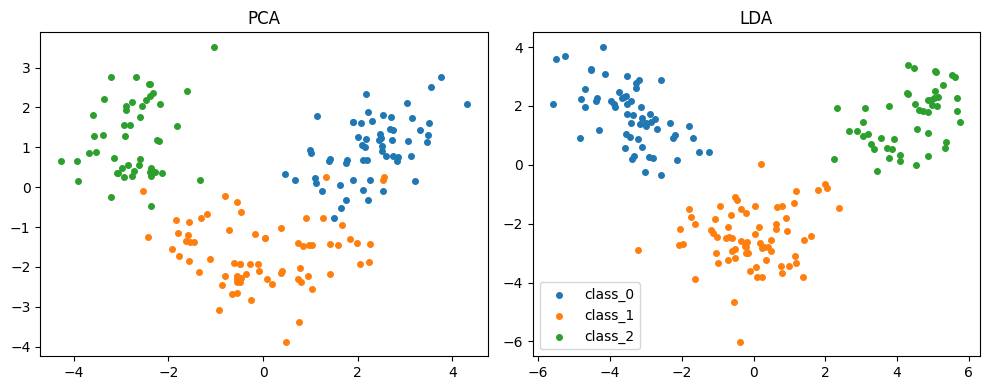

In [15]:
fig,axs=plt.subplots(1,2,figsize=(10,4))
for cls in sorted(set(y)):
    axs[0].scatter(*X_pca[y==cls].T,s=16,label=wine.target_names[cls])
    axs[1].scatter(*X_lda[y==cls].T,s=16,label=wine.target_names[cls])
axs[0].set_title('PCA'); axs[1].set_title('LDA')
axs[1].legend(); plt.tight_layout(); plt.show()

**Interpretation**

Both projections compress the observations, yet their visible patterns differ because their optimization targets are not the same. The labels used for LDA mean its projection must be learned only from training data in a predictive workflow.

## 6. t-SNE and data visualization

t-distributed stochastic neighbor embedding emphasizes local neighborhoods in a low-dimensional display. It is mainly an exploratory visualization method; distances between distant clusters may not have a simple global meaning.

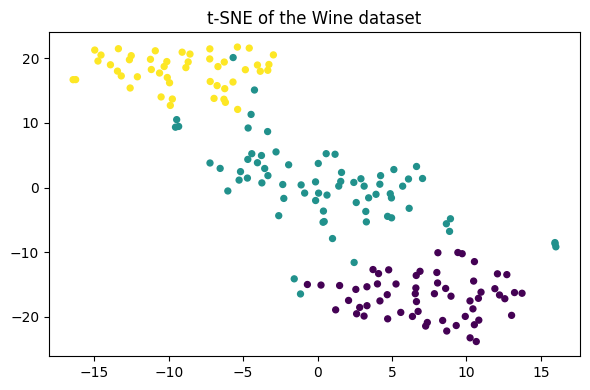

In [16]:
from sklearn.manifold import TSNE
embedding = TSNE(n_components=2, perplexity=20, random_state=42, init='pca', learning_rate='auto').fit_transform(X)
plt.figure(figsize=(6,4))
plt.scatter(embedding[:,0],embedding[:,1],c=y,cmap='viridis',s=18)
plt.title('t-SNE of the Wine dataset'); plt.tight_layout(); plt.show()

**Interpretation**

The arrangement highlights which observations have similar neighborhoods. The positions and gaps depend on the t-SNE settings, so the visualization should be interpreted cautiously rather than as a measurable global distance map.

## 7. Guidelines for selecting dimensionality reduction techniques

Technique selection depends on whether labels are available and whether the goal is visualization, compression or prediction. PCA is a common compression baseline; LDA is supervised; t-SNE is primarily for visualization.

In [17]:
from sklearn.decomposition import PCA
full = PCA().fit(X)
print('Components needed for >= 90% variance:',
      int((full.explained_variance_ratio_.cumsum()<0.90).sum()+1))
print('First five cumulative ratios:',full.explained_variance_ratio_.cumsum()[:5].round(3))

Components needed for >= 90% variance: 8
First five cumulative ratios: [0.362 0.554 0.665 0.736 0.802]


**Interpretation**

The variance threshold offers a practical criterion for choosing the number of PCA components. This criterion measures retained variance, not necessarily whether a downstream classifier will improve.

## 8. Impact on model performance

Reducing dimension can change prediction accuracy and computational cost. Fair comparison requires identical training and testing observations and fitting the reduction step only on training data.

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
baseline = make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000))
reduced = make_pipeline(StandardScaler(),PCA(n_components=5),LogisticRegression(max_iter=1000))
for label, estimator in [('All features',baseline),('PCA (5 components)',reduced)]:
    scores=cross_val_score(estimator,wine.data,y,cv=5)
    print(label, 'mean accuracy:', round(scores.mean(),3))

All features mean accuracy: 0.983
PCA (5 components) mean accuracy: 0.978


**Interpretation**

Cross-validation provides a comparable estimate of predictive accuracy for the two workflows. PCA can reduce input size, but any accuracy gain or loss should be assessed rather than assumed.

## Book recipe: PCA transformation and explained variance

Following the book’s PCA recipe, the wine dataset is standardized before reducing the feature space. We also inspect the variance captured by the first two principal components.

In [19]:
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np
wine_book = load_wine()
X_wine_book = StandardScaler().fit_transform(wine_book.data)
pca_book = PCA(n_components=2)
X_pca_book = pca_book.fit_transform(X_wine_book)
print('Original:', X_wine_book.shape, 'PCA:', X_pca_book.shape)
print('Explained variance ratio:', np.round(pca_book.explained_variance_ratio_, 4))

Original: (178, 13) PCA: (178, 2)
Explained variance ratio: [0.362  0.1921]


**Interpretation**

PCA compresses the original measurements into two uncorrelated axes. Explained variance quantifies how much variation in the standardized data is represented by these axes, not how much class-label information they retain.

## Book recipe: LDA for supervised class separation

In contrast to PCA, linear discriminant analysis uses the known wine classes while choosing projection directions.

In [20]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
lda_book = LinearDiscriminantAnalysis(n_components=2)
X_lda_book = lda_book.fit_transform(X_wine_book, wine_book.target)
print('LDA projection:', X_lda_book.shape)
print('LDA explained variance ratio:', np.round(lda_book.explained_variance_ratio_,4))

LDA projection: (178, 2)
LDA explained variance ratio: [0.6875 0.3125]


**Interpretation**

The resulting two-dimensional representation is optimized for discrimination among the three target classes rather than maximizing overall variance. This explains why PCA and LDA may produce visibly different group arrangements.